In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score
)

from sklearn.ensemble import RandomForestClassifier

In [2]:
df = pd.read_csv("../data/ai4i2020.csv")

df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

target = "Machine failure"

X = df.drop(columns=[
    "UDI",
    "Product ID",
    "Machine failure",
    "TWF",
    "HDF",
    "PWF",
    "OSF",
    "RNF"
])

y = df[target]

categorical_features = ["Type"]

numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

X_train_df = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_test_df = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

print(X_train_df.shape)
print(X_test_df.shape)

(8000, 8)
(2000, 8)


In [4]:
rf_all = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_all.fit(X_train_df, y_train)

y_pred_all = rf_all.predict(X_test_df)
y_prob_all = rf_all.predict_proba(X_test_df)[:, 1]

In [5]:
selected_features = [
    "num__Air temperature [K]",
    "num__Process temperature [K]",
    "num__Rotational speed [rpm]",
    "num__Torque [Nm]",
    "num__Tool wear [min]"
]

X_train_selected = X_train_df[selected_features]
X_test_selected = X_test_df[selected_features]

rf_selected = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_selected.fit(X_train_selected, y_train)

y_pred_selected = rf_selected.predict(X_test_selected)
y_prob_selected = rf_selected.predict_proba(X_test_selected)[:, 1]

In [6]:
cm_all = confusion_matrix(y_test, y_pred_all)

cm_selected = confusion_matrix(y_test, y_pred_selected)

print("Random Forest - All Features")
print(cm_all)

print("\nRandom Forest - Selected Features")
print(cm_selected)

Random Forest - All Features
[[1886   46]
 [  17   51]]

Random Forest - Selected Features
[[1874   58]
 [  14   54]]


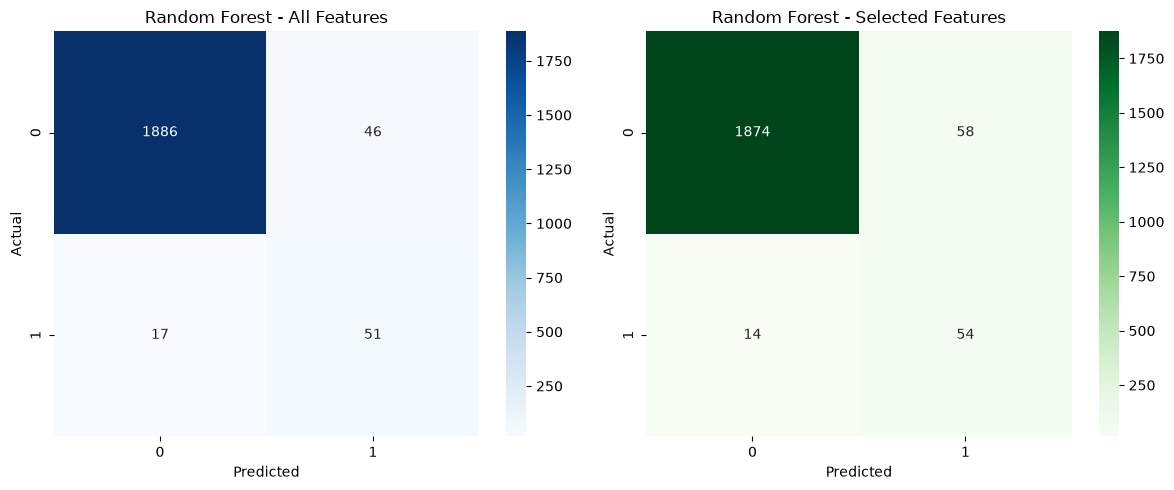

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    cm_all,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0]
)

axes[0].set_title("Random Forest - All Features")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    cm_selected,
    annot=True,
    fmt="d",
    cmap="Greens",
    ax=axes[1]
)

axes[1].set_title("Random Forest - Selected Features")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [8]:
print("RANDOM FOREST — ALL FEATURES")
print(classification_report(y_test, y_pred_all))

print("\n" + "="*60 + "\n")

print("RANDOM FOREST — SELECTED FEATURES")
print(classification_report(y_test, y_pred_selected))

RANDOM FOREST — ALL FEATURES
              precision    recall  f1-score   support

           0       0.99      0.98      0.98      1932
           1       0.53      0.75      0.62        68

    accuracy                           0.97      2000
   macro avg       0.76      0.86      0.80      2000
weighted avg       0.98      0.97      0.97      2000



RANDOM FOREST — SELECTED FEATURES
              precision    recall  f1-score   support

           0       0.99      0.97      0.98      1932
           1       0.48      0.79      0.60        68

    accuracy                           0.96      2000
   macro avg       0.74      0.88      0.79      2000
weighted avg       0.98      0.96      0.97      2000



In [9]:
print(cm_all)
print(cm_selected)

[[1886   46]
 [  17   51]]
[[1874   58]
 [  14   54]]


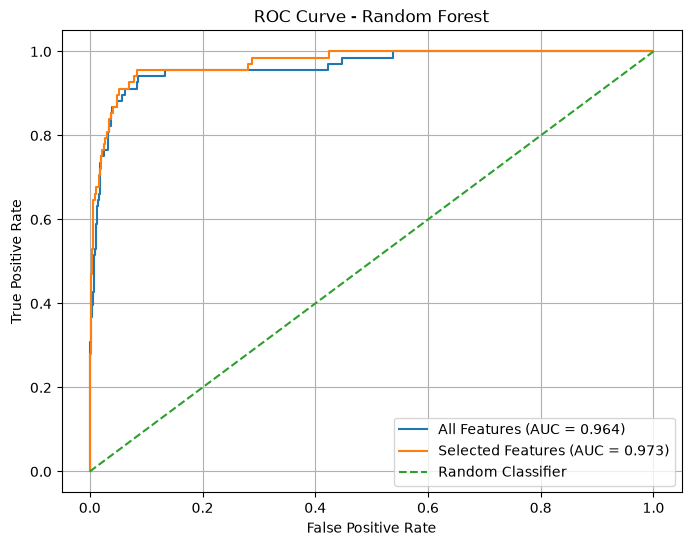

In [10]:
from sklearn.metrics import roc_curve, roc_auc_score

# ROC curve - All Features
fpr_all, tpr_all, _ = roc_curve(y_test, y_prob_all)
roc_auc_all = roc_auc_score(y_test, y_prob_all)

# ROC curve - Selected Features
fpr_selected, tpr_selected, _ = roc_curve(y_test, y_prob_selected)
roc_auc_selected = roc_auc_score(y_test, y_prob_selected)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_all,
    tpr_all,
    label=f"All Features (AUC = {roc_auc_all:.3f})"
)

plt.plot(
    fpr_selected,
    tpr_selected,
    label=f"Selected Features (AUC = {roc_auc_selected:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest")
plt.legend()
plt.grid()
plt.show()

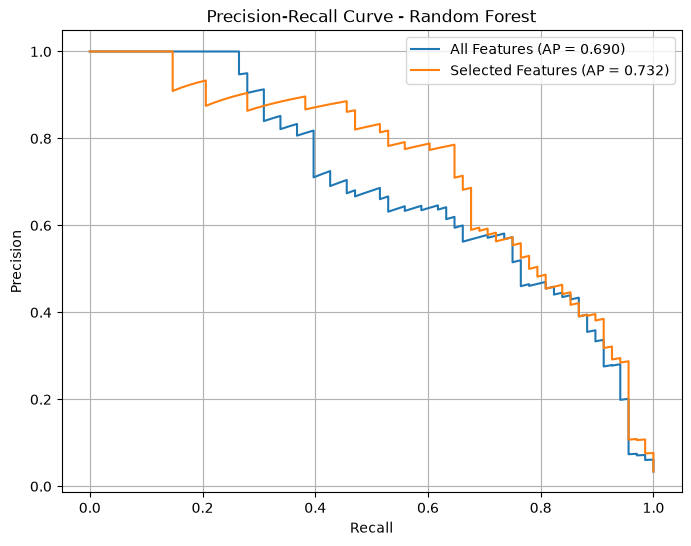

In [11]:
from sklearn.metrics import precision_recall_curve, average_precision_score

precision_all, recall_all, _ = precision_recall_curve(
    y_test,
    y_prob_all
)

precision_selected, recall_selected, _ = precision_recall_curve(
    y_test,
    y_prob_selected
)

ap_all = average_precision_score(y_test, y_prob_all)
ap_selected = average_precision_score(y_test, y_prob_selected)

plt.figure(figsize=(8, 6))

plt.plot(
    recall_all,
    precision_all,
    label=f"All Features (AP = {ap_all:.3f})"
)

plt.plot(
    recall_selected,
    precision_selected,
    label=f"Selected Features (AP = {ap_selected:.3f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Random Forest")
plt.legend()
plt.grid()
plt.show()

In [12]:
importance_df = pd.DataFrame({
    "Feature": selected_features,
    "Importance": rf_selected.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

importance_df

,Feature,Importance
3,num__Torque [Nm],0.343549
2,num__Rotational speed [rpm],0.306533
4,num__Tool wear [min],0.226355
0,num__Air temperature [K],0.076771
1,num__Process temperature [K],0.046793


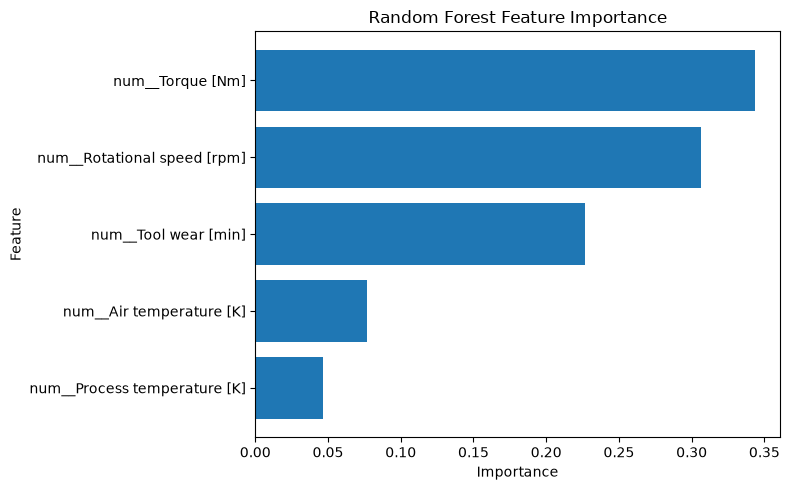

In [13]:
plt.figure(figsize=(8, 5))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [14]:
final_comparison = pd.DataFrame({
    "Model": [
        "Random Forest - All Features",
        "Random Forest - Selected Features"
    ],
    "Accuracy": [
        0.9685,
        0.9640
    ],
    "Precision": [
        0.525773,
        0.482143
    ],
    "Recall": [
        0.750000,
        0.794118
    ],
    "F1 Score": [
        0.618182,
        0.600000
    ],
    "ROC-AUC": [
        0.963913,
        0.973176
    ]
})

final_comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest - All Features,0.9685,0.525773,0.750000,0.618182,0.963913
1,Random Forest - Selected Features,0.9640,0.482143,0.794118,0.600000,0.973176


In [15]:
final_comparison.to_csv(
    "../results/final_model_comparison.csv",
    index=False
)

importance_df.to_csv(
    "../results/feature_importance.csv",
    index=False
)

print("Evaluation results saved successfully.")

Evaluation results saved successfully.


In [16]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, mutual_info_classif

In [17]:
preprocessor_final = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

In [18]:
final_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

In [19]:
X_final = df[final_features]
y_final = df["Machine failure"]

In [20]:
X_train_final, X_test_final, y_train_final, y_test_final = train_test_split(
    X_final,
    y_final,
    test_size=0.20,
    random_state=42,
    stratify=y_final
)

In [21]:
final_pipeline = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "model",
        RandomForestClassifier(
            n_estimators=200,
            max_depth=10,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        )
    )
])

In [22]:
final_pipeline.fit(
    X_train_final,
    y_train_final
)

print("Final model trained successfully.")

Final model trained successfully.


In [23]:
final_predictions = final_pipeline.predict(X_test_final)

final_probabilities = final_pipeline.predict_proba(
    X_test_final
)[:, 1]

In [24]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

final_accuracy = accuracy_score(
    y_test_final,
    final_predictions
)

final_precision = precision_score(
    y_test_final,
    final_predictions
)

final_recall = recall_score(
    y_test_final,
    final_predictions
)

final_f1 = f1_score(
    y_test_final,
    final_predictions
)

final_roc_auc = roc_auc_score(
    y_test_final,
    final_probabilities
)

print("Final Model Performance")
print("-----------------------")
print(f"Accuracy : {final_accuracy:.4f}")
print(f"Precision: {final_precision:.4f}")
print(f"Recall   : {final_recall:.4f}")
print(f"F1 Score : {final_f1:.4f}")
print(f"ROC-AUC  : {final_roc_auc:.4f}")

Final Model Performance
-----------------------
Accuracy : 0.9640
Precision: 0.4821
Recall   : 0.7941
F1 Score : 0.6000
ROC-AUC  : 0.9732


In [25]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(
    final_pipeline,
    "../models/final_model.pkl"
)

print("Final model saved successfully.")

Final model saved successfully.


In [26]:
sample_machine = pd.DataFrame({
    "Air temperature [K]": [298.5],
    "Process temperature [K]": [308.2],
    "Rotational speed [rpm]": [1500],
    "Torque [Nm]": [45.0],
    "Tool wear [min]": [120]
})

prediction = final_pipeline.predict(sample_machine)[0]

probability = final_pipeline.predict_proba(
    sample_machine
)[0][1]

print("Prediction:", prediction)
print(f"Failure Probability: {probability:.2%}")

Prediction: 0
Failure Probability: 0.07%
